# Assignment 3 — Association Rule Mining

**Dataset:** `bread_basket.csv` (20,507 item rows; 9,465 distinct transactions)

Fill in the short answer cells and run the code cells. This notebook generates the required tables and figures.

**Sections:**
1. Setup & Data Load
2. EDA (a–e)
3. Frequent Itemset Mining (FP-Growth)
4. Association Rules + Report Table
5. Rule Subgraph (Bread, Coffee, Cake, Tea)
6. Interpretation Prompt

## 1) Setup & Data Load (10 pts)
- Place `bread_basket.csv` in the same folder as this notebook **or** update the path below.
- Needed packages: `pandas`, `matplotlib`, `mlxtend`, `networkx` (for the small graph).
- If a package is missing, run the `pip install` cell.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from mlxtend.frequent_patterns import association_rules, fpgrowth

DATA_PATH = Path("bread_basket.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}")

data = pd.read_csv(DATA_PATH)
data["item"] = data["item"].astype("string").str.strip()
data = data.dropna(subset=["transaction", "item"])
data["transaction"] = data["transaction"].astype(int)

print(f"Loaded {len(data):,} item rows across {data['transaction'].nunique():,} transactions.")
display(data.head())

Loaded 20,507 item rows across 9,465 transactions.


,transaction,item,date_time,time,period_day,weekday_weekend
0,1,Bread,30/10/2016,9:58,morning,weekend
1,2,Scandinavian,30/10/2016,10:05,morning,weekend
2,2,Scandinavian,30/10/2016,10:05,morning,weekend
3,3,Hot chocolate,30/10/2016,10:07,morning,weekend
4,3,Jam,30/10/2016,10:07,morning,weekend


## 2) EDA (a–e) (30 pts)
### a) List variables and their dtypes (5 pts)

In [2]:
print("Variables and data types")
display(data.dtypes.rename("dtype").to_frame())
print(f"\nRows: {len(data):,}; columns: {data.shape[1]}")

Variables and data types


,dtype
transaction,int64
item,string
date_time,str
time,str
period_day,str
weekday_weekend,str



Rows: 20,507; columns: 6


### b) "Statistics" overview (5 pts)
Use `describe(include='all')` as a stand‑in for Statistics.

In [3]:
display(data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction,20507.0,NaN,NaN,NaN,4976.20237,2796.203001,1.0,2552.0,5137.0,7357.0,9684.0
item,20507,94,Coffee,5471,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_time,20507,159,2017-02-04,292,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,20507,1255,11:06,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
period_day,20507,4,afternoon,11569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekday_weekend,20507,2,weekday,12807,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### c) Bar plot — count of **unique transactions per item** (10 pts)
Set the subtitle to your **FirstName LastName**.

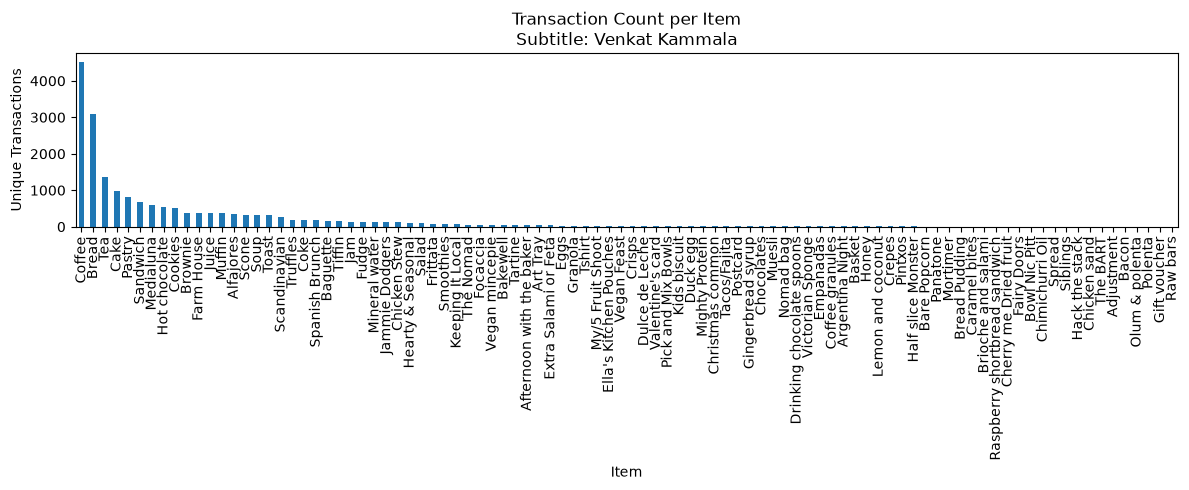

In [ ]:
# Count each item at most once in each transaction.
subtitle = "Arya Kumar"
unique_transaction_items = data[["transaction", "item"]].drop_duplicates()
item_counts = unique_transaction_items["item"].value_counts().sort_values(ascending=False)

ax = item_counts.plot(kind="bar", figsize=(12, 5))
plt.title(f"Transaction Count per Item\nSubtitle: {subtitle}")
plt.xlabel("Item")
plt.ylabel("Unique Transactions")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### d) Report counts for Coffee, Tea, Alfajores, Juice, and Chicken Stew (10 pts)

In [5]:
items_to_report = ["Coffee", "Tea", "Alfajores", "Juice", "Chicken Stew"]
reported_counts = item_counts.reindex(items_to_report, fill_value=0).rename("unique_transactions")
display(reported_counts.to_frame())

,unique_transactions
item,
Coffee,4528
Tea,1350
Alfajores,344
Juice,365
Chicken Stew,123


### e) Transaction basket-size overview
Summarize and plot the number of distinct items in each transaction.

,distinct_items_per_transaction
count,9465.000000
mean,1.995457
std,1.129543
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,10.000000


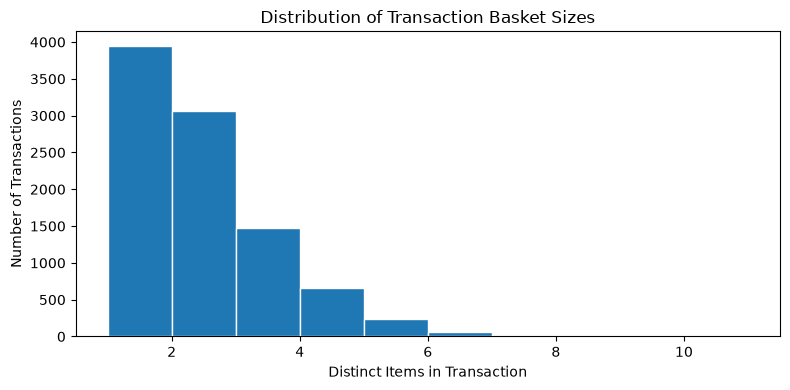

In [6]:
basket_sizes = unique_transaction_items.groupby("transaction")["item"].nunique()
display(basket_sizes.describe().rename("distinct_items_per_transaction").to_frame())

ax = basket_sizes.plot(kind="hist", bins=range(1, int(basket_sizes.max()) + 2), figsize=(8, 4), edgecolor="white")
ax.set_title("Distribution of Transaction Basket Sizes")
ax.set_xlabel("Distinct Items in Transaction")
ax.set_ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

## 3) Frequent Itemset Mining with FP-Growth (min_support = 0.02) (25 pts)
We pivot the data to a **transaction × item** one-hot table (boolean), then run FP-Growth.

In [7]:
# One row per transaction, one boolean column per item.
basket = pd.crosstab(unique_transaction_items["transaction"], unique_transaction_items["item"]).astype(bool)

min_support = 0.02
frequent_itemsets = fpgrowth(basket, min_support=min_support, use_colnames=True)
frequent_itemsets["itemset_size"] = frequent_itemsets["itemsets"].map(len)
frequent_itemsets = frequent_itemsets.sort_values(["support", "itemset_size"], ascending=[False, True])

print(f"Basket matrix: {basket.shape[0]:,} transactions x {basket.shape[1]:,} items")
print(f"Frequent itemsets at support >= {min_support:.0%}: {len(frequent_itemsets):,}")
display(frequent_itemsets.head(20))

Basket matrix: 9,465 transactions x 94 items
Frequent itemsets at support >= 2%: 33


,support,itemsets,itemset_size
5,0.478394,frozenset({Coffee}),1
0,0.327205,frozenset({Bread}),1
8,0.142631,frozenset({Tea}),1
12,0.103856,frozenset({Cake}),1
19,0.090016,"frozenset({Coffee, Bread})",2
6,0.086107,frozenset({Pastry}),1
13,0.071844,frozenset({Sandwich}),1
7,0.061807,frozenset({Medialuna}),1
2,0.058320,frozenset({Hot chocolate}),1
28,0.054728,"frozenset({Coffee, Cake})",2


## 4) Association Rules + Report Table (25 pts)
Metric: confidence; selected min_threshold = 0.30 to retain rules with at least 30% confidence.

In [9]:
min_confidence = 0.30
rules = association_rules(
    frequent_itemsets.drop(columns="itemset_size"),
    metric="confidence",
    min_threshold=min_confidence,
)

# Keep the measures used for interpretation and stringify itemsets for a readable report.
report = rules[["antecedents", "consequents", "support", "confidence", "lift", "leverage"]].copy()
report["antecedents"] = report["antecedents"].map(lambda items: ", ".join(sorted(items)))
report["consequents"] = report["consequents"].map(lambda items: ", ".join(sorted(items)))
report = report.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

print(f"Confidence threshold: {min_confidence:.0%}; rules found: {len(report):,}")
display(report.head(30).round({
    "support": 4,
    "confidence": 4,
    "lift": 2,
    "leverage": 4,
}))

Confidence threshold: 30%; rules found: 10


,antecedents,consequents,support,confidence,lift,leverage
0,Toast,Coffee,0.0237,0.7044,1.47,0.0076
1,Medialuna,Coffee,0.0352,0.5692,1.19,0.0056
2,Pastry,Coffee,0.0475,0.5521,1.15,0.0064
3,Juice,Coffee,0.0206,0.5342,1.12,0.0022
4,Sandwich,Coffee,0.0382,0.5324,1.11,0.0039
5,Cake,Coffee,0.0547,0.5270,1.10,0.0050
6,Cookies,Coffee,0.0282,0.5184,1.08,0.0022
7,Hot chocolate,Coffee,0.0296,0.5072,1.06,0.0017
8,Pastry,Bread,0.0292,0.3387,1.03,0.0010
9,Tea,Coffee,0.0499,0.3496,0.73,-0.0184


## 5) Rule Subgraph (Bread, Coffee, Cake, Tea) (5 pts)
Plot directed one-to-one association rules among the four requested items. Edge labels show confidence.

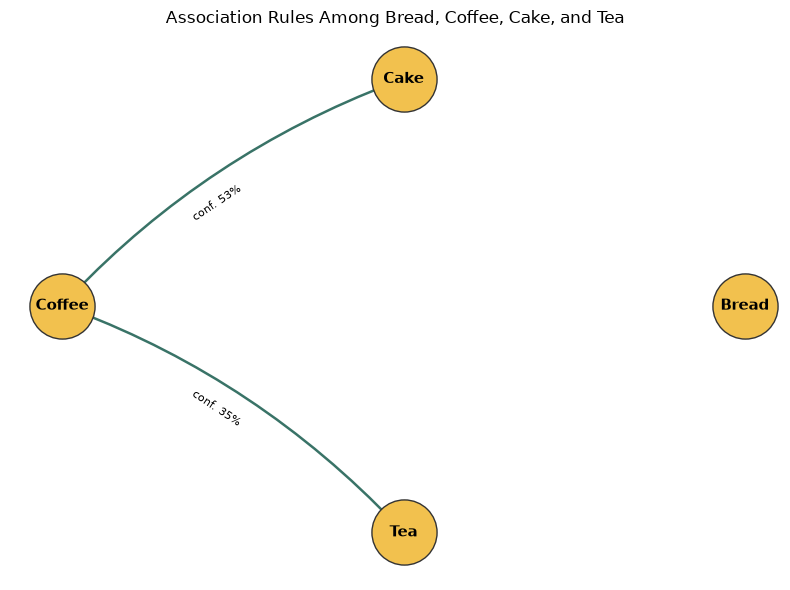

Displayed 2 directed rules meeting support >= 2% and confidence >= 30%.


In [10]:
focus_items = {"Bread", "Coffee", "Cake", "Tea"}
focus_rules = rules[
    rules["antecedents"].map(lambda items: len(items) == 1 and items <= focus_items)
    & rules["consequents"].map(lambda items: len(items) == 1 and items <= focus_items)
].copy()

rule_graph = nx.DiGraph()
rule_graph.add_nodes_from(sorted(focus_items))
for _, rule in focus_rules.iterrows():
    source = next(iter(rule["antecedents"]))
    target = next(iter(rule["consequents"]))
    rule_graph.add_edge(source, target, confidence=rule["confidence"], lift=rule["lift"])

positions = nx.circular_layout(rule_graph)
plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(rule_graph, positions, node_size=2200, node_color="#f2c14e", edgecolors="#333333")
nx.draw_networkx_labels(rule_graph, positions, font_size=11, font_weight="bold")
nx.draw_networkx_edges(
    rule_graph,
    positions,
    arrows=True,
    arrowsize=18,
    width=1.8,
    connectionstyle="arc3,rad=0.12",
    edge_color="#397367",
)
edge_labels = {(source, target): f"conf. {attrs['confidence']:.0%}" for source, target, attrs in rule_graph.edges(data=True)}
nx.draw_networkx_edge_labels(rule_graph, positions, edge_labels=edge_labels, font_size=8, label_pos=0.55)
plt.title("Association Rules Among Bread, Coffee, Cake, and Tea")
plt.axis("off")
plt.tight_layout()
plt.show()
print(f"Displayed {rule_graph.number_of_edges()} directed rules meeting support >= {min_support:.0%} and confidence >= {min_confidence:.0%}.")

## 6) Interpretation Prompt (5 pts)
**Interpret the rule {Coffee, Cake} ⇒ {Bread} in plain English.**

- **Support**: What fraction of all transactions contain Coffee, Cake, and Bread together?
- **Confidence**: Among baskets with Coffee and Cake, what share also include Bread?
- **Lift > 1** implies positive association; comment on practical meaning.

The next cell calculates these measures directly from the transaction matrix and prints a data-grounded interpretation.

In [11]:
antecedent_mask = basket["Coffee"] & basket["Cake"]
rule_mask = antecedent_mask & basket["Bread"]
rule_support = rule_mask.mean()
rule_confidence = rule_mask.sum() / antecedent_mask.sum() if antecedent_mask.sum() else float("nan")
bread_support = basket["Bread"].mean()
rule_lift = rule_confidence / bread_support if bread_support else float("nan")

print(f"Coffee and Cake baskets: {antecedent_mask.sum():,}")
print(f"Coffee, Cake, and Bread baskets: {rule_mask.sum():,}")
print(f"Support: {rule_support:.3%} of all {len(basket):,} transactions")
print(f"Confidence: {rule_confidence:.1%} of Coffee-and-Cake transactions also contain Bread")
print(f"Lift: {rule_lift:.2f} (Bread baseline transaction share: {bread_support:.1%})")
if rule_lift > 1:
    print("Interpretation: Coffee-and-Cake baskets contain Bread more often than the average basket. This is a positive association, not evidence that buying Coffee and Cake causes Bread purchases.")
elif rule_lift < 1:
    print("Interpretation: Coffee-and-Cake baskets contain Bread less often than the average basket, so this is a negative association in this dataset.")
else:
    print("Interpretation: Coffee-and-Cake baskets contain Bread at about the dataset-wide baseline rate, indicating little association.")

if rule_support < min_support:
    print(f"Note: This specific three-item combination is below the FP-Growth support cutoff ({min_support:.0%}), so it is interpreted from the raw basket matrix rather than the mined rule table.")

Coffee and Cake baskets: 518
Coffee, Cake, and Bread baskets: 95
Support: 1.004% of all 9,465 transactions
Confidence: 18.3% of Coffee-and-Cake transactions also contain Bread
Lift: 0.56 (Bread baseline transaction share: 32.7%)
Interpretation: Coffee-and-Cake baskets contain Bread less often than the average basket, so this is a negative association in this dataset.
Note: This specific three-item combination is below the FP-Growth support cutoff (2%), so it is interpreted from the raw basket matrix rather than the mined rule table.
